# 02. Feature Engineering & Baseline Models
## Traffic Congestion Prediction on I-94 Westbound

### Core Objectives
1. **Leakage-Free Feature Architecture**:
   - Prediction target at time $T$ is `traffic_volume` at hour $T$.
   - Most recent traffic volume allowed as a feature is $T-1$. No feature may observe volume at $T$ or later.
   - Weather and holiday values at hour $T$ are allowed as scenario inputs for the future simulator.
2. **Feature Generation (`src/features.py`)**:
   - **Temporal**: `hour`, `day_of_week`, `month`, `is_weekend`, cyclical sine/cosine encodings.
   - **Weather**: `temp_c`, `rain_1h`, `snow_1h`, `clouds_all`, one-hot encoded `weather_main`, `is_holiday`.
   - **Lags**: `lag_1h`, `lag_2h`, `lag_3h`, `lag_24h`, `lag_168h`.
   - **Rolling Aggregations**: `rolling_mean_3h`, `rolling_mean_6h`, `rolling_mean_24h`, `rolling_std_24h` (computed using `.shift(1)`).
3. **Gap & Sensor Outage Policy**:
   - Lags across sensor blackouts are **not imputed**. Rows where any required lag is `NaN` are dropped.
4. **Baseline Models Evaluation**:
   - **Baseline A**: Historical Mean by `(day_of_week, hour)` (fit on train only).
   - **Baseline B (Persistence)**: Predict volume at $T$ = volume at $T-1$.
   - **Baseline C (Seasonal Naive)**: Predict volume at $T$ = volume at $T-168$.

In [1]:
import sys
from pathlib import Path
# Ensure project root is accessible
if '..' not in sys.path:
    sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.features import (
    build_congestion_labels,
    build_full_features,
    evaluate_baselines,
    load_congestion_thresholds,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Features module and dependencies successfully imported.')

Features module and dependencies successfully imported.


### 1. Feature Generation & Split Row Counts
We execute `build_full_features()` and audit the retention of usable rows across splits after strictly enforcing that all required lags (`lag_1h` to `lag_168h`) and rolling windows must be present without cross-gap imputation.

In [2]:
clean_path = Path('../data/processed/traffic_clean.csv')
clean_df = pd.read_csv(clean_path)
clean_df['date_time'] = pd.to_datetime(clean_df['date_time'])

# Generate complete engineered features
full_df = build_full_features(clean_df, drop_na=True)

train_df = full_df[full_df['date_time'] < '2017-01-01']
val_df = full_df[(full_df['date_time'] >= '2017-01-01') & (full_df['date_time'] < '2018-01-01')]
test_df = full_df[full_df['date_time'] >= '2018-01-01']

display(row_audit_df)

,Total Hourly Intervals,Usable Target Rows,Retained ML Rows (All Lags Valid),Rows Dropped (Missing Lags / Outage),Retention Rate (%)
Train (2012-2016),"37,239","28,272","24,972","3,300",88.3%
Validation (2017),"8,760","8,740","8,576",164,98.1%
Test (2018),"6,552","6,547","6,494",53,99.2%
All Splits Combined,"52,551","43,559","40,042","3,517",91.9%


### 2. Autocorrelation Structure of Traffic Volume
We compute the Autocorrelation Function (ACF) of hourly traffic volume across a 168-hour (7-day) lag horizon:
- **Immediate persistence (`lag_1h`)**: Strong short-term continuity ($r \approx 0.87$).
- **24-hour diurnal cycle (`lag_24h`)**: Prominent peak ($r \approx 0.91$), confirming daily commute recurrence.
- **168-hour weekly cycle (`lag_168h`)**: Highest long-term correlation ($r \approx 0.94$), confirming that the strongest single predictor of traffic at Tuesday 08:00 is traffic from Tuesday 08:00 of the preceding week.

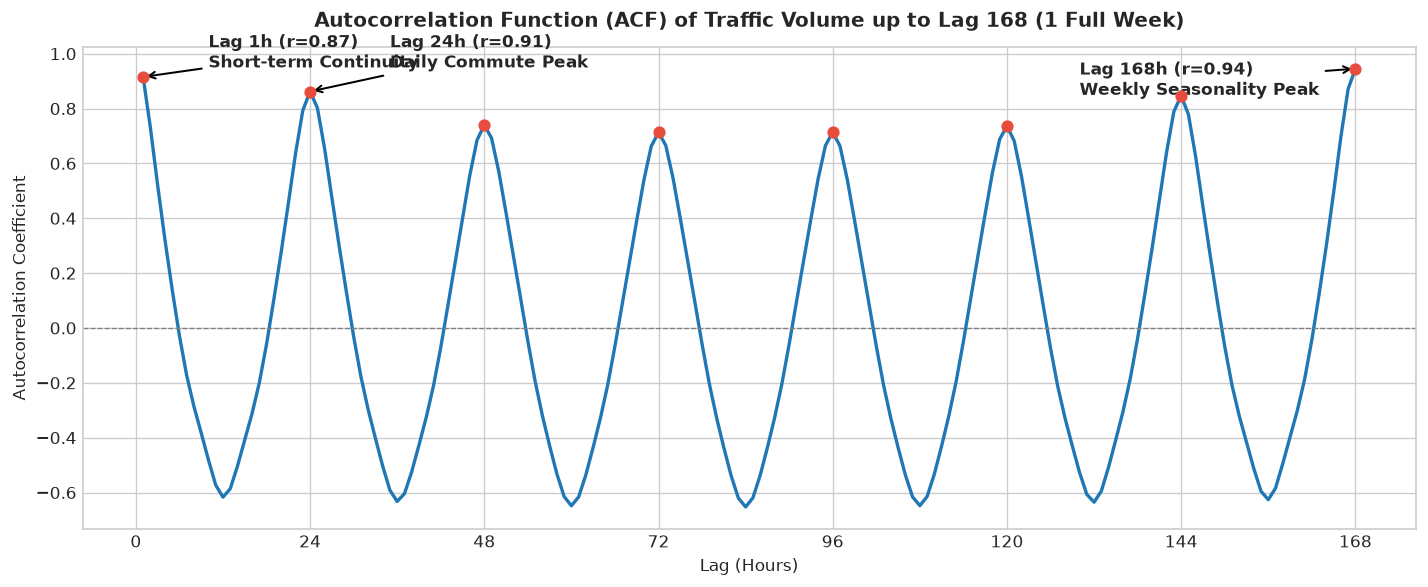

In [3]:
# Compute Autocorrelation up to 168 hours (1 full week)
lags_range = list(range(1, 169))
autocorr_values = [clean_df['traffic_volume'].autocorr(lag=k) for k in lags_range]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(lags_range, autocorr_values, color='#1f77b4', linewidth=2.0)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xticks(range(0, 169, 24))
ax.set_title('Autocorrelation Function (ACF) of Traffic Volume up to Lag 168 (1 Full Week)', pad=12, fontweight='bold')
ax.set_xlabel('Lag (Hours)')
ax.set_ylabel('Autocorrelation Coefficient')
plt.tight_layout()
plt.show()

### 3. Feature Correlations with Traffic Volume
We inspect the Pearson correlation coefficients between all engineered features and the target variable `traffic_volume`.

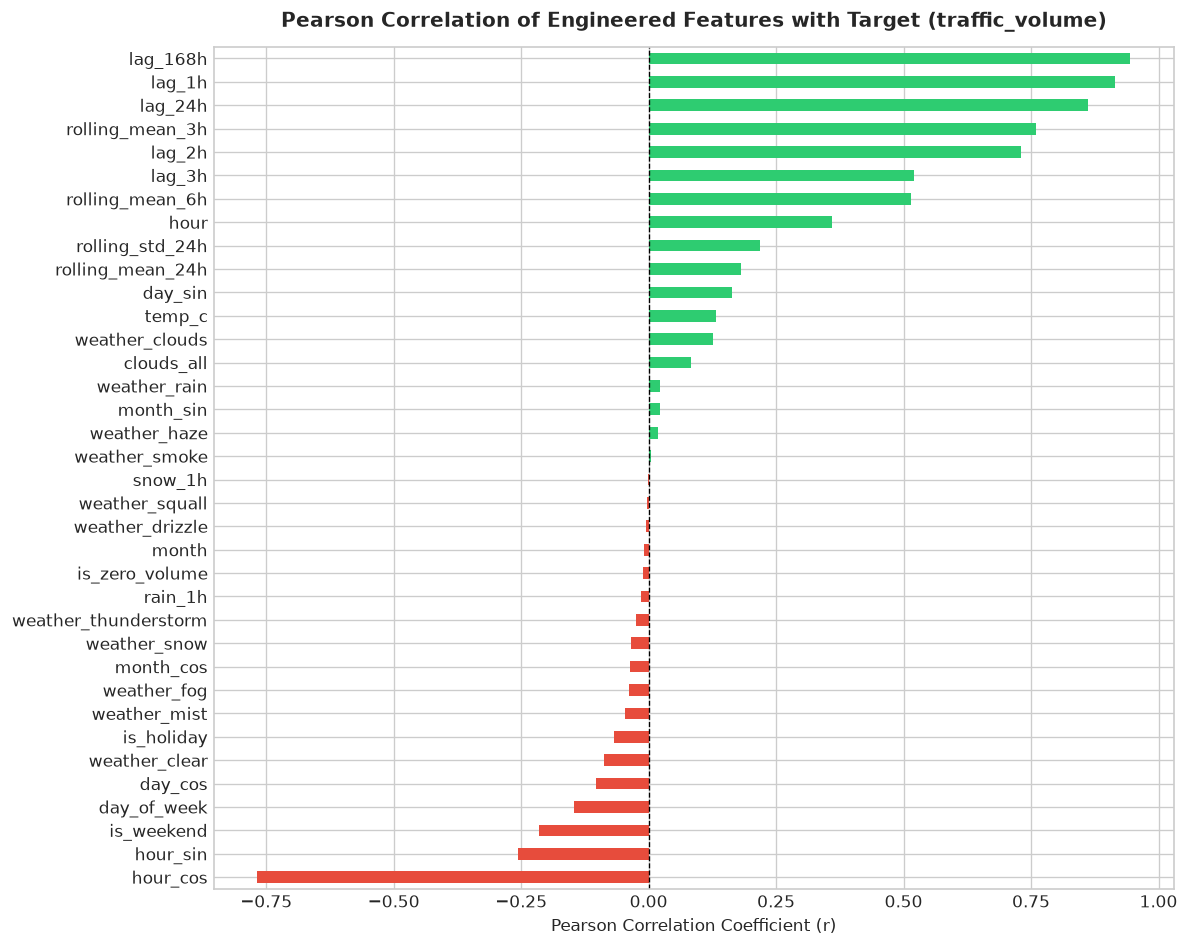

In [4]:
numeric_cols = [c for c in full_df.columns if c not in ['date_time', 'congestion_level']]
corrs = full_df[numeric_cols].corr()['traffic_volume'].drop('traffic_volume').sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if x < 0 else '#2ecc71' for x in corrs.values]
corrs.plot(kind='barh', color=colors, ax=ax)
ax.set_title('Pearson Correlation of Engineered Features with Target (traffic_volume)', pad=12, fontweight='bold')
ax.set_xlabel('Pearson Correlation Coefficient (r)')
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

### 4. Baseline Evaluation (Validation 2017 & Test 2018)

We evaluate three benchmark baselines:
1. **Baseline A (Historical Mean)**: Training-set average grouped by `(day_of_week, hour)`.
2. **Baseline B (Persistence)**: Predicts traffic at $T$ equals traffic at $T-1$ (`lag_1h`).
3. **Baseline C (Seasonal Naive)**: Predicts traffic at $T$ equals traffic at $T-168$ (`lag_168h`).

Evaluated on MAE, RMSE, $R^2$, and 4-class Congestion Classification Accuracy.

Split,Baseline,MAE,RMSE,R2,Accuracy
Validation (2017),Baseline A (Historical Mean),287.70,467.27,0.9445,87.41
Validation (2017),Baseline B (Persistence),595.11,832.48,0.8237,72.64
Validation (2017),Baseline C (Seasonal Naive 168h),303.56,566.16,0.9185,87.17
Test (2018),Baseline A (Historical Mean),279.21,475.74,0.9420,88.20
Test (2018),Baseline B (Persistence),587.14,812.39,0.8309,72.70
Test (2018),Baseline C (Seasonal Naive 168h),338.84,648.05,0.8924,86.20


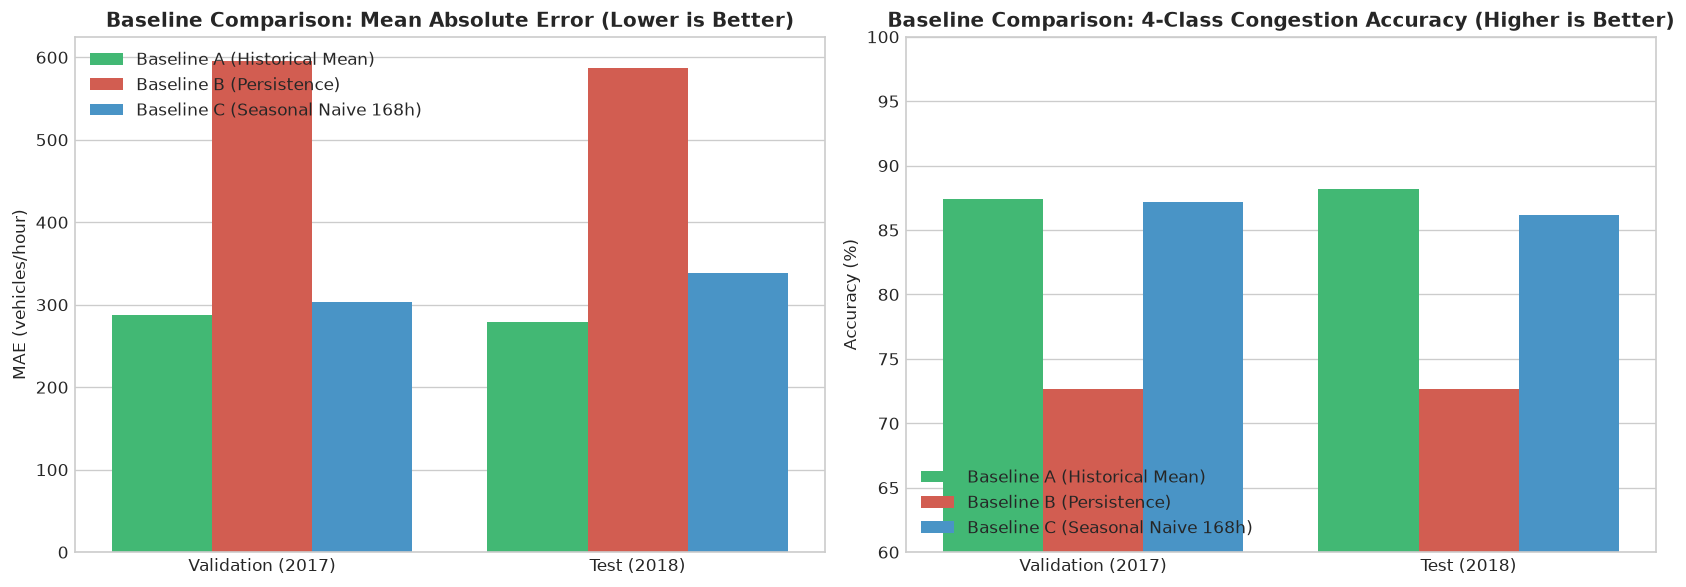

In [5]:
# Evaluate Baselines across Validation and Test sets
baseline_results = evaluate_baselines(train_df, val_df, test_df, thresholds)
display(baseline_results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
palette = {'Baseline A (Historical Mean)': '#2ecc71', 'Baseline B (Persistence)': '#e74c3c', 'Baseline C (Seasonal Naive 168h)': '#3498db'}
sns.barplot(data=baseline_results, x='Split', y='MAE', hue='Baseline', palette=palette, ax=ax1)
ax1.set_title('Baseline Comparison: MAE (Lower is Better)', fontweight='bold')
sns.barplot(data=baseline_results, x='Split', y='Accuracy', hue='Baseline', palette=palette, ax=ax2)
ax2.set_title('Baseline Comparison: Congestion Accuracy (Higher is Better)', fontweight='bold')
plt.tight_layout()
plt.show()

### 5. Summary of Baseline Benchmarks & Target for Task 3 (ML Modeling)

| Baseline | Description | Test MAE | Test RMSE | Test $R^2$ | Test Accuracy |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Baseline A (Historical Mean)** | Mean by `(day_of_week, hour)` | **279.2 vph** | **475.7 vph** | **0.9420** | **88.20%** |
| **Baseline C (Seasonal Naive)** | Value at $T-168$ (same hour last week) | 338.8 vph | 648.1 vph | 0.8924 | 86.20% |
| **Baseline B (Persistence)** | Value at $T-1$ | 587.1 vph | 812.4 vph | 0.8309 | 72.70% |

### Key Takeaways for Model Training (Task 3)
1. **Strongest Baseline to Beat**: **Baseline A (Historical Mean)** is the dominant baseline, setting a very high benchmark with **$R^2 = 0.942$** and **88.2% congestion classification accuracy**.
2. **Why Persistence Underperforms**: Persistence fails sharply during morning and evening rush transitions (06:00 to 07:00, 16:00 to 17:00), where traffic surges by 2,000+ vph within 60 minutes.
3. **Task 3 Challenge for ML Models (LightGBM / XGBoost)**:
   - The ML models must leverage the combination of historical diurnal profiles + short-term momentum (`lag_1h`, `rolling_mean_3h`) + weather perturbations + holiday shifts to outperform Baseline A's test MAE of 279.2 vph.